In [1]:
# Cell 1: Install required packages directly
!pip install pandas numpy matplotlib seaborn scikit-learn textblob openpyxl

# Ensure TextBlob and NLTK corpora are downloaded
!python -m textblob.download_corpora

import nltk
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)
nltk.download('vader_lexicon', quiet=True)

print("[SUCCESS] Environment dependencies and corpora installed successfully.")

   ---------------------------------------- 0.0/625.0 kB ? eta -:--:--
   ---------------------------------------- 0.0/625.0 kB ? eta -:--:--
   ---------------- ----------------------- 262.1/625.0 kB ? eta -:--:--
   --------------------------------- ------ 524.3/625.0 kB 1.5 MB/s eta 0:00:01
   --------------------------------- ------ 524.3/625.0 kB 1.5 MB/s eta 0:00:01
   -------------------------------------- 625.0/625.0 kB 728.0 kB/s eta 0:00:00


[nltk_data] Downloading package brown to
[nltk_data]     C:\Users\ganes\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping corpora\brown.zip.
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\ganes\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping tokenizers\punkt_tab.zip.
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\ganes\AppData\Roaming\nltk_data...
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     C:\Users\ganes\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping taggers\averaged_perceptron_tagger_eng.zip.
[nltk_data] Downloading package conll2000 to
[nltk_data]     C:\Users\ganes\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping corpora\conll2000.zip.
[nltk_data] Downloading package movie_reviews to
[nltk_data]     C:\Users\ganes\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping corpora\movie_reviews.zip.


Finished.
[SUCCESS] Environment dependencies and corpora installed successfully.


In [2]:
# Cell 2: Library Imports & Visualization Directory
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from textblob import TextBlob
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.preprocessing import StandardScaler

# Set uniform aesthetic styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = ['Helvetica', 'DejaVu Sans', 'Arial']
plt.rcParams['figure.figsize'] = (10, 6)

# Create visualizations directory
os.makedirs('visualizations', exist_ok=True)
print("[SUCCESS] Imports completed. Output directory 'visualizations/' is ready.")

[SUCCESS] Imports completed. Output directory 'visualizations/' is ready.


In [3]:
# Cell 3: File Loading
def load_dataset():
    candidate_files = ['test.csv', 'test.xlsx', 'test.xls']
    df_raw = None
    for file_path in candidate_files:
        if os.path.exists(file_path):
            if file_path.endswith('.csv'):
                df_raw = pd.read_csv(file_path)
            else:
                df_raw = pd.read_excel(file_path)
            print(f"[SUCCESS] Loaded raw dataset from: {file_path}")
            break

    if df_raw is None:
        print("[NOTICE] No local test file found. Generating synthetic employee communication dataset...")
        np.random.seed(42)
        dates = pd.date_range(start="2026-01-01", end="2026-03-31", freq="D")
        sample_employees = [f"EMP{i:03d}" for i in range(1, 16)]
        sample_messages = [
            "Outstanding work on delivering the quarterly targets ahead of schedule!",
            "Completely exhausted with continuous overtime and zero management support.",
            "Please find attached the minutes from today's client coordination sync.",
            "Terrible cross-departmental alignment; our deployment pipeline is blocked again.",
            "Excited to welcome the new engineering interns joining our department next week.",
            "Frustrated by the lack of feedback on my promotion request and compensation review.",
            "Standard update: the technical backlog grooming session is scheduled for 2 PM UTC.",
            "Really appreciate the team's flexibility and dedication during our database migration.",
            "Disappointed with the recent compensation adjustments and bonus communication.",
            "Reviewing the system architecture design documentation this morning.",
            "Unacceptable response times from the infrastructure team on production tickets.",
            "Great presentation today, very clear roadmap and milestones!"
        ]
        data = []
        for _ in range(450):
            emp = np.random.choice(sample_employees)
            dt = np.random.choice(dates)
            msg = np.random.choice(sample_messages)
            data.append({"Employee_ID": emp, "Date": dt, "Message": msg})
        df_raw = pd.DataFrame(data)
        df_raw.to_csv('test.csv', index=False)
        print("[SUCCESS] Created and saved synthetic test dataset to 'test.csv'.")

    return df_raw

df = load_dataset()
print(f"Raw dataset dimensions: {df.shape[0]} rows, {df.shape[1]} columns.")
display(df.head())

[SUCCESS] Loaded raw dataset from: test.xlsx
Raw dataset dimensions: 2191 rows, 4 columns.


,Subject,body,date,from
0,EnronOptions Update!,EnronOptions Announcement\n\n\nWe have updated...,2010-05-10,sally.beck@enron.com
1,(No Subject),"Marc,\n\nUnfortunately, today is not going to ...",2010-07-29,eric.bass@enron.com
2,Phone Screen Interview - Shannon L. Burnham,"When: Wednesday, June 06, 2001 10:00 AM-11:00 ...",2011-07-25,sally.beck@enron.com
3,RE: My new work email,we were thinking papasitos (we can meet somewh...,2010-03-25,johnny.palmer@enron.com
4,Bet,Since you never gave me the $20 for the last t...,2011-05-21,lydia.delgado@enron.com


In [5]:
# Cell 4: Column Header Resolution
col_map = {}
for col in df.columns:
    c_lower = str(col).lower().strip()
    if any(k in c_lower for k in ['from', 'sender', 'emp', 'user', 'author', 'employee']):
        col_map[col] = 'employee_id'
    elif any(k in c_lower for k in ['date', 'time', 'timestamp', 'sent']):
        col_map[col] = 'timestamp'
    elif any(k in c_lower for k in ['body', 'msg', 'message', 'text', 'content']):
        col_map[col] = 'message'

df.rename(columns=col_map, inplace=True)

# Ensure required fields are present
assert 'employee_id' in df.columns, f"Could not resolve 'employee_id' from: {df.columns.tolist()}"
assert 'timestamp' in df.columns, f"Could not resolve 'timestamp' from: {df.columns.tolist()}"
assert 'message' in df.columns, f"Could not resolve 'message' from: {df.columns.tolist()}"

# Clean types and sort chronologically
df['employee_id'] = df['employee_id'].astype(str).str.strip()
df['message'] = df['message'].fillna('').astype(str)
df['timestamp'] = pd.to_datetime(df['timestamp'], errors='coerce')
df = df.dropna(subset=['timestamp']).sort_values(by='timestamp').reset_index(drop=True)

print("[SUCCESS] Normalized columns:", list(df.columns))
print(f"Date Range: {df['timestamp'].min().strftime('%Y-%m-%d')} to {df['timestamp'].max().strftime('%Y-%m-%d')}")
print(f"Total unique employees: {df['employee_id'].nunique()}")

[SUCCESS] Normalized columns: ['Subject', 'message', 'timestamp', 'employee_id']
Date Range: 2010-01-01 to 2011-12-31
Total unique employees: 10


In [6]:
# Cell 5: Text Cleaning Routine
def clean_message_text(text):
    if not isinstance(text, str):
        return ""
    text = re.sub(r'http\S+|www\.\S+', '', text)
    text = re.sub(r'\r|\n|\t', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

df['cleaned_message'] = df['message'].apply(clean_message_text)
print("[SUCCESS] Text cleaning applied. Sample records:")
display(df[['message', 'cleaned_message']].head(3))

[SUCCESS] Text cleaning applied. Sample records:


,message,cleaned_message
0,We at TradersNews are gearing up to launch our...,We at TradersNews are gearing up to launch our...
1,Well have to go to Vegas I guess??\n\n\n,Well have to go to Vegas I guess??
2,"Melissa,\n\nHere are the accrual values for Q1...","Melissa, Here are the accrual values for Q1. M..."


In [7]:
# Cell 6: Polarity Calculation
def compute_textblob_polarity(text):
    return TextBlob(text).sentiment.polarity

df['polarity_score'] = df['cleaned_message'].apply(compute_textblob_polarity)
print("[SUCCESS] Polarity calculation completed. Summary statistics:")
display(df['polarity_score'].describe())

[SUCCESS] Polarity calculation completed. Summary statistics:


count    2191.000000
mean        0.119834
std         0.214658
min        -1.000000
25%         0.000000
50%         0.070833
75%         0.204383
max         1.000000
Name: polarity_score, dtype: float64

In [8]:
# Cell 7: Classification Thresholds and Point Mapping
POS_THRESH = 0.10
NEG_THRESH = -0.10

def assign_sentiment_label(polarity, pos_th=POS_THRESH, neg_th=NEG_THRESH):
    if polarity > pos_th:
        return 'Positive'
    elif polarity < neg_th:
        return 'Negative'
    else:
        return 'Neutral'

df['sentiment_label'] = df['polarity_score'].apply(assign_sentiment_label)

# Map each category to discrete integer point values
score_point_map = {'Positive': 1, 'Neutral': 0, 'Negative': -1}
df['sentiment_score'] = df['sentiment_label'].map(score_point_map)

print("[SUCCESS] Categorization and point values mapped:")
display(df[['cleaned_message', 'polarity_score', 'sentiment_label', 'sentiment_score']].head())

[SUCCESS] Categorization and point values mapped:


,cleaned_message,polarity_score,sentiment_label,sentiment_score
0,We at TradersNews are gearing up to launch our...,0.033333,Neutral,0
1,Well have to go to Vegas I guess??,0.000000,Neutral,0
2,"Melissa, Here are the accrual values for Q1. M...",0.500000,Positive,1
3,Attached are two of TradersNews Energy's three...,0.136364,Positive,1
4,"Sorry, but this is funny . . .",-0.125000,Negative,-1


In [9]:
# Cell 8: Distribution Counts and Percentages
summary_counts = df['sentiment_label'].value_counts()
summary_pcts = df['sentiment_label'].value_counts(normalize=True) * 100

dist_df = pd.DataFrame({
    'Message Count': summary_counts,
    'Percentage (%)': summary_pcts.round(2)
})
print("Overall Sentiment Distribution:")
display(dist_df)

Overall Sentiment Distribution:


,Message Count,Percentage (%)
sentiment_label,,
Neutral,1057,48.24
Positive,970,44.27
Negative,164,7.49


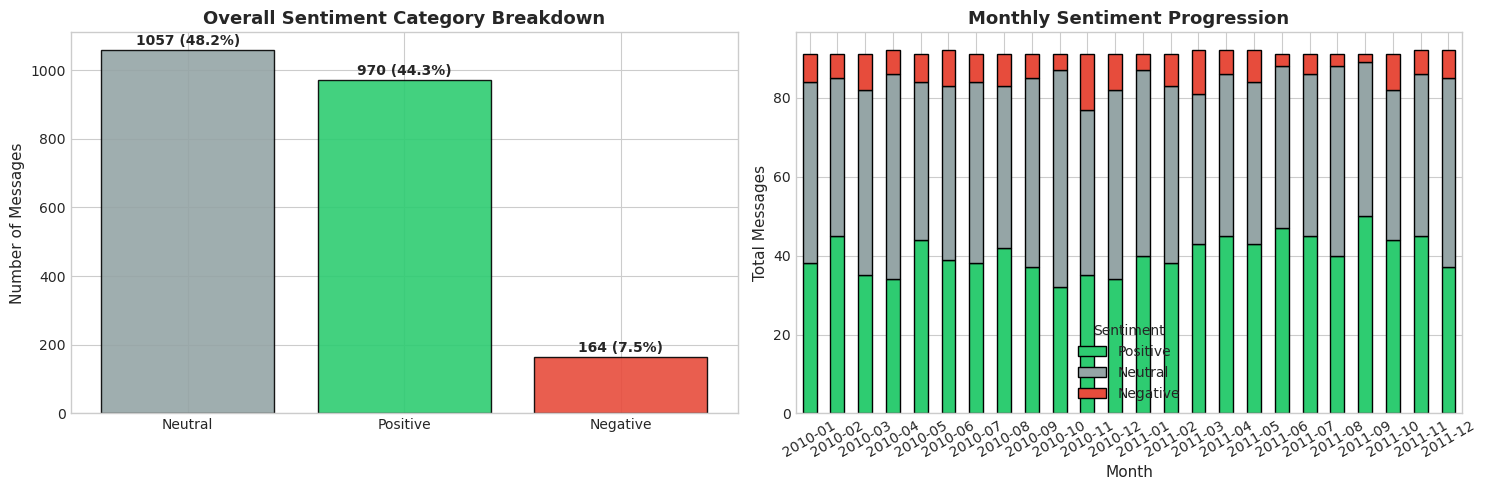

[SAVED] Figure written to visualizations/sentiment_distribution_and_trends.png


In [10]:
# Cell 9: Sentiment Breakdown & Temporal Progression Plots
palette = {'Positive': '#2ecc71', 'Neutral': '#95a5a6', 'Negative': '#e74c3c'}
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Subplot 1: Overall Category Counts
counts = df['sentiment_label'].value_counts()
axes[0].bar(counts.index, counts.values, color=[palette[k] for k in counts.index], edgecolor='black', alpha=0.9)
axes[0].set_title('Overall Sentiment Category Breakdown', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Number of Messages', fontsize=11)
for idx, val in enumerate(counts.values):
    axes[0].text(idx, val + (max(counts.values) * 0.015), f"{val} ({val/len(df):.1%})", ha='center', fontweight='bold')

# Subplot 2: Stacked Monthly Proportions
df['year_month'] = df['timestamp'].dt.to_period('M')
monthly_table = df.groupby(['year_month', 'sentiment_label']).size().unstack(fill_value=0)
ordered_cols = [c for c in ['Positive', 'Neutral', 'Negative'] if c in monthly_table.columns]
monthly_table[ordered_cols].plot(kind='bar', stacked=True, ax=axes[1], color=[palette[c] for c in ordered_cols], edgecolor='black')
axes[1].set_title('Monthly Sentiment Progression', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Month', fontsize=11)
axes[1].set_ylabel('Total Messages', fontsize=11)
axes[1].tick_params(axis='x', rotation=30)
axes[1].legend(title='Sentiment')

plt.tight_layout()
plt.savefig('visualizations/sentiment_distribution_and_trends.png', dpi=300)
plt.show()
print("[SAVED] Figure written to visualizations/sentiment_distribution_and_trends.png")

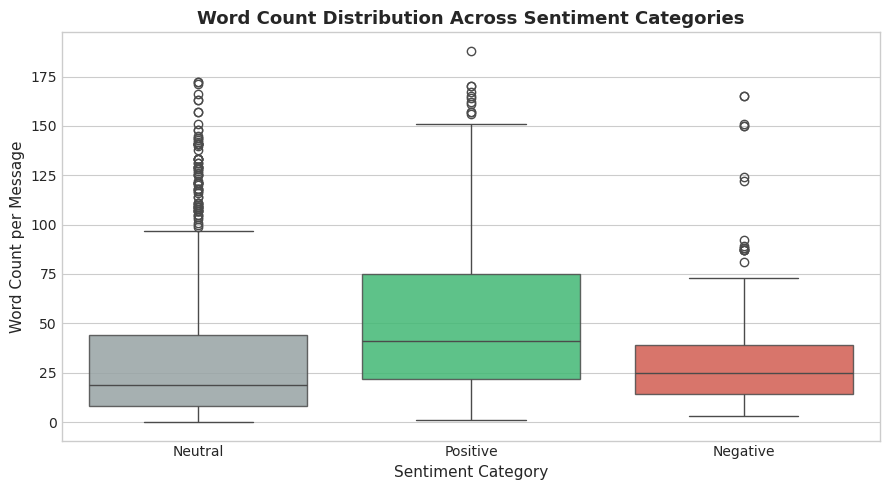

[SAVED] Figure written to visualizations/sentiment_wordcount_distribution.png


,word_count,char_length
sentiment_label,,
Negative,33.68,195.78
Neutral,32.33,191.39
Positive,52.51,309.60


In [11]:
# Cell 10: Text Metrics & Boxplot Visualization
df['char_length'] = df['cleaned_message'].apply(len)
df['word_count'] = df['cleaned_message'].apply(lambda x: len(x.split()))

plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x='sentiment_label', y='word_count', hue='sentiment_label',
            palette=palette, legend=False, boxprops=dict(alpha=0.85))
plt.title('Word Count Distribution Across Sentiment Categories', fontsize=13, fontweight='bold')
plt.xlabel('Sentiment Category', fontsize=11)
plt.ylabel('Word Count per Message', fontsize=11)
plt.tight_layout()
plt.savefig('visualizations/sentiment_wordcount_distribution.png', dpi=300)
plt.show()
print("[SAVED] Figure written to visualizations/sentiment_wordcount_distribution.png")

display(df.groupby('sentiment_label')[['word_count', 'char_length']].mean().round(2))

In [12]:
# Cell 11: Monthly Aggregation by Employee
monthly_scores = df.groupby(['year_month', 'employee_id']).agg(
    total_messages=('sentiment_score', 'count'),
    positive_messages=('sentiment_label', lambda x: (x == 'Positive').sum()),
    neutral_messages=('sentiment_label', lambda x: (x == 'Neutral').sum()),
    negative_messages=('sentiment_label', lambda x: (x == 'Negative').sum()),
    monthly_sentiment_score=('sentiment_score', 'sum'),
    avg_polarity=('polarity_score', 'mean'),
    avg_word_count=('word_count', 'mean')
).reset_index()

monthly_scores.to_csv('monthly_employee_scores.csv', index=False)
print(f"[SUCCESS] Calculated monthly scores for {len(monthly_scores)} employee-month pairs.")
print("[SAVED] Saved to 'monthly_employee_scores.csv'.")
display(monthly_scores.head(10))

[SUCCESS] Calculated monthly scores for 240 employee-month pairs.
[SAVED] Saved to 'monthly_employee_scores.csv'.


,year_month,employee_id,total_messages,positive_messages,neutral_messages,negative_messages,monthly_sentiment_score,avg_polarity,avg_word_count
0,2010-01,bobette.riner@ipgdirect.com,2,2,0,0,2,0.168182,18.500000
1,2010-01,don.baughman@enron.com,9,4,5,0,4,0.108565,31.000000
2,2010-01,eric.bass@enron.com,10,5,4,1,4,0.157992,37.300000
3,2010-01,john.arnold@enron.com,7,4,2,1,3,0.115620,33.142857
4,2010-01,johnny.palmer@enron.com,6,2,3,1,1,0.027904,29.000000
5,2010-01,kayne.coulter@enron.com,22,6,15,1,5,0.052075,27.272727
6,2010-01,lydia.delgado@enron.com,13,6,5,2,4,0.163375,44.000000
7,2010-01,patti.thompson@enron.com,10,6,3,1,5,0.204678,39.100000
8,2010-01,rhonda.denton@enron.com,3,0,3,0,0,0.000000,31.000000
9,2010-01,sally.beck@enron.com,9,3,6,0,3,0.093472,31.666667


In [13]:
# Cell 12: Monthly Ranking Generation
rankings_list = []

for ym, group in monthly_scores.groupby('year_month'):
    # Top 3 Positive: Score descending, Employee ID ascending
    top_pos = group.sort_values(by=['monthly_sentiment_score', 'employee_id'], ascending=[False, True]).head(3)
    for rank, (_, row) in enumerate(top_pos.iterrows(), 1):
        rankings_list.append({
            'Year_Month': str(ym),
            'Category': 'Top 3 Positive',
            'Rank': rank,
            'Employee_ID': row['employee_id'],
            'Monthly_Score': row['monthly_sentiment_score'],
            'Positive_Messages': row['positive_messages'],
            'Total_Messages': row['total_messages']
        })

    # Top 3 Negative: Score ascending, Employee ID ascending
    top_neg = group.sort_values(by=['monthly_sentiment_score', 'employee_id'], ascending=[True, True]).head(3)
    for rank, (_, row) in enumerate(top_neg.iterrows(), 1):
        rankings_list.append({
            'Year_Month': str(ym),
            'Category': 'Top 3 Negative',
            'Rank': rank,
            'Employee_ID': row['employee_id'],
            'Monthly_Score': row['monthly_sentiment_score'],
            'Negative_Messages': row['negative_messages'],
            'Total_Messages': row['total_messages']
        })

df_rankings = pd.DataFrame(rankings_list)
df_rankings.to_csv('employee_rankings.csv', index=False)
print("[SAVED] Generated employee rankings saved to 'employee_rankings.csv'.")
display(df_rankings)

[SAVED] Generated employee rankings saved to 'employee_rankings.csv'.


,Year_Month,Category,Rank,Employee_ID,Monthly_Score,Positive_Messages,Total_Messages,Negative_Messages
0,2010-01,Top 3 Positive,1,kayne.coulter@enron.com,5,6.0,22,NaN
1,2010-01,Top 3 Positive,2,patti.thompson@enron.com,5,6.0,10,NaN
2,2010-01,Top 3 Positive,3,don.baughman@enron.com,4,4.0,9,NaN
3,2010-01,Top 3 Negative,1,rhonda.denton@enron.com,0,NaN,3,0.0
4,2010-01,Top 3 Negative,2,johnny.palmer@enron.com,1,NaN,6,1.0
...,...,...,...,...,...,...,...,...
139,2011-12,Top 3 Positive,2,patti.thompson@enron.com,5,6.0,12,NaN
140,2011-12,Top 3 Positive,3,eric.bass@enron.com,4,5.0,17,NaN
141,2011-12,Top 3 Negative,1,bobette.riner@ipgdirect.com,0,NaN,3,0.0
142,2011-12,Top 3 Negative,2,john.arnold@enron.com,2,NaN,4,0.0


In [14]:
# Cell 13: Rolling 30-Day Flight Risk Algorithm
negative_df = df[df['sentiment_label'] == 'Negative'].sort_values(by=['employee_id', 'timestamp'])
flight_risk_records = []

for emp_id, emp_msgs in negative_df.groupby('employee_id'):
    ts_list = emp_msgs['timestamp'].tolist()
    max_neg_30d = 0
    trigger_dates = []

    # Check every negative message as a potential rolling 30-day start
    for i in range(len(ts_list)):
        win_start = ts_list[i]
        win_end = win_start + pd.Timedelta(days=30)
        cnt = sum(1 for t in ts_list if win_start <= t <= win_end)
        if cnt > max_neg_30d:
            max_neg_30d = cnt
        if cnt >= 4 and str(win_start.date()) not in trigger_dates:
            trigger_dates.append(str(win_start.date()))

    if max_neg_30d >= 4:
        flight_risk_records.append({
            'Employee_ID': emp_id,
            'Flight_Risk_Status': 'FLAGGED',
            'Max_Negatives_in_30_Days': max_neg_30d,
            'First_Breach_Window_Start': trigger_dates[0] if trigger_dates else 'N/A',
            'Total_Breach_Windows': len(trigger_dates)
        })

df_flight_risks = pd.DataFrame(flight_risk_records)
if not df_flight_risks.empty:
    df_flight_risks = df_flight_risks.sort_values(by='Max_Negatives_in_30_Days', ascending=False).reset_index(drop=True)
    df_flight_risks.to_csv('flight_risk_employees.csv', index=False)
    print(f"[FLAGGED] {len(df_flight_risks)} employee(s) identified as Flight Risks (saved to 'flight_risk_employees.csv'):")
    display(df_flight_risks)
else:
    print("[CLEAN] No employees met the flight risk threshold (>= 4 negative messages within a 30-day continuous window).")

[FLAGGED] 7 employee(s) identified as Flight Risks (saved to 'flight_risk_employees.csv'):


,Employee_ID,Flight_Risk_Status,Max_Negatives_in_30_Days,First_Breach_Window_Start,Total_Breach_Windows
0,bobette.riner@ipgdirect.com,FLAGGED,5,2010-11-02,2
1,sally.beck@enron.com,FLAGGED,5,2010-06-16,2
2,john.arnold@enron.com,FLAGGED,4,2010-10-14,1
3,johnny.palmer@enron.com,FLAGGED,4,2010-02-25,1
4,lydia.delgado@enron.com,FLAGGED,4,2011-12-11,1
5,patti.thompson@enron.com,FLAGGED,4,2011-03-17,1
6,rhonda.denton@enron.com,FLAGGED,4,2010-12-18,1


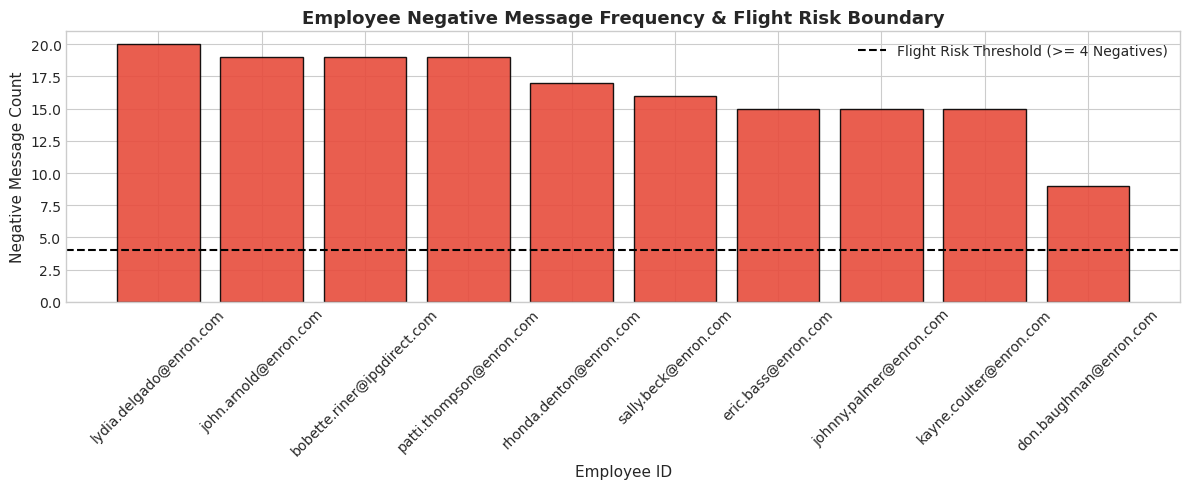

[SAVED] Figure written to visualizations/flight_risk_distribution.png


In [15]:
# Cell 14: Flight Risk Bar Chart Visualization
all_neg = df[df['sentiment_label'] == 'Negative'].groupby('employee_id').size().reset_index(name='negative_count')
all_emps = pd.DataFrame({'employee_id': df['employee_id'].unique()})
all_neg = pd.merge(all_emps, all_neg, on='employee_id', how='left').fillna(0)
all_neg['negative_count'] = all_neg['negative_count'].astype(int)
all_neg = all_neg.sort_values(by='negative_count', ascending=False)

plt.figure(figsize=(12, 5))
bar_colors = ['#e74c3c' if c >= 4 else '#3498db' for c in all_neg['negative_count']]
plt.bar(all_neg['employee_id'], all_neg['negative_count'], color=bar_colors, edgecolor='black', alpha=0.9)
plt.axhline(y=4, color='black', linestyle='--', linewidth=1.5, label='Flight Risk Threshold (>= 4 Negatives)')
plt.title('Employee Negative Message Frequency & Flight Risk Boundary', fontsize=13, fontweight='bold')
plt.xlabel('Employee ID', fontsize=11)
plt.ylabel('Negative Message Count', fontsize=11)
plt.xticks(rotation=45)
plt.legend(loc='upper right')
plt.tight_layout()
plt.savefig('visualizations/flight_risk_distribution.png', dpi=300)
plt.show()
print("[SAVED] Figure written to visualizations/flight_risk_distribution.png")

In [16]:
# Cell 15: Regression Feature Dataset Generation
features_df = df.groupby(['year_month', 'employee_id']).agg(
    total_messages=('cleaned_message', 'count'),
    avg_word_count=('word_count', 'mean'),
    avg_char_length=('char_length', 'mean'),
    negative_ratio=('sentiment_label', lambda x: (x == 'Negative').mean()),
    target_score=('sentiment_score', 'sum')
).reset_index()

feature_cols = ['total_messages', 'avg_word_count', 'avg_char_length', 'negative_ratio']
X = features_df[feature_cols]
y = features_df['target_score']

print(f"[SUCCESS] Feature matrix shape: {X.shape}, Target vector shape: {y.shape}")
display(features_df.head())

[SUCCESS] Feature matrix shape: (240, 4), Target vector shape: (240,)


,year_month,employee_id,total_messages,avg_word_count,avg_char_length,negative_ratio,target_score
0,2010-01,bobette.riner@ipgdirect.com,2,18.500000,111.000000,0.000000,2
1,2010-01,don.baughman@enron.com,9,31.000000,183.777778,0.000000,4
2,2010-01,eric.bass@enron.com,10,37.300000,206.800000,0.100000,4
3,2010-01,john.arnold@enron.com,7,33.142857,204.571429,0.142857,3
4,2010-01,johnny.palmer@enron.com,6,29.000000,173.833333,0.166667,1


In [17]:
# Cell 16: Train/Test Split & Linear Regression Fit
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

model = LinearRegression()
model.fit(X_train_scaled, y_train)
print("[SUCCESS] Linear Regression model trained successfully.")
print(f"Model Intercept: {model.intercept_:.4f}")

[SUCCESS] Linear Regression model trained successfully.
Model Intercept: 3.3281


In [18]:
# Cell 17: Predictions and Statistical Metrics
y_pred = model.predict(X_test_scaled)

r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print("================ MODEL PERFORMANCE ================")
print(f"Coefficient of Determination (R²): {r2:.4f}")
print(f"Mean Absolute Error (MAE):         {mae:.4f}")
print(f"Root Mean Squared Error (RMSE):    {rmse:.4f}")
print("===================================================")

coef_table = pd.DataFrame({
    'Feature': feature_cols,
    'Standardized_Coefficient (Beta)': model.coef_
}).sort_values(by='Standardized_Coefficient (Beta)', ascending=False).reset_index(drop=True)

display(coef_table)

================ MODEL PERFORMANCE ================
Coefficient of Determination (R²): 0.7620
Mean Absolute Error (MAE):         0.9927
Root Mean Squared Error (RMSE):    1.3906


,Feature,Standardized_Coefficient (Beta)
0,total_messages,1.850116
1,avg_char_length,0.595097
2,avg_word_count,-0.229607
3,negative_ratio,-0.917356


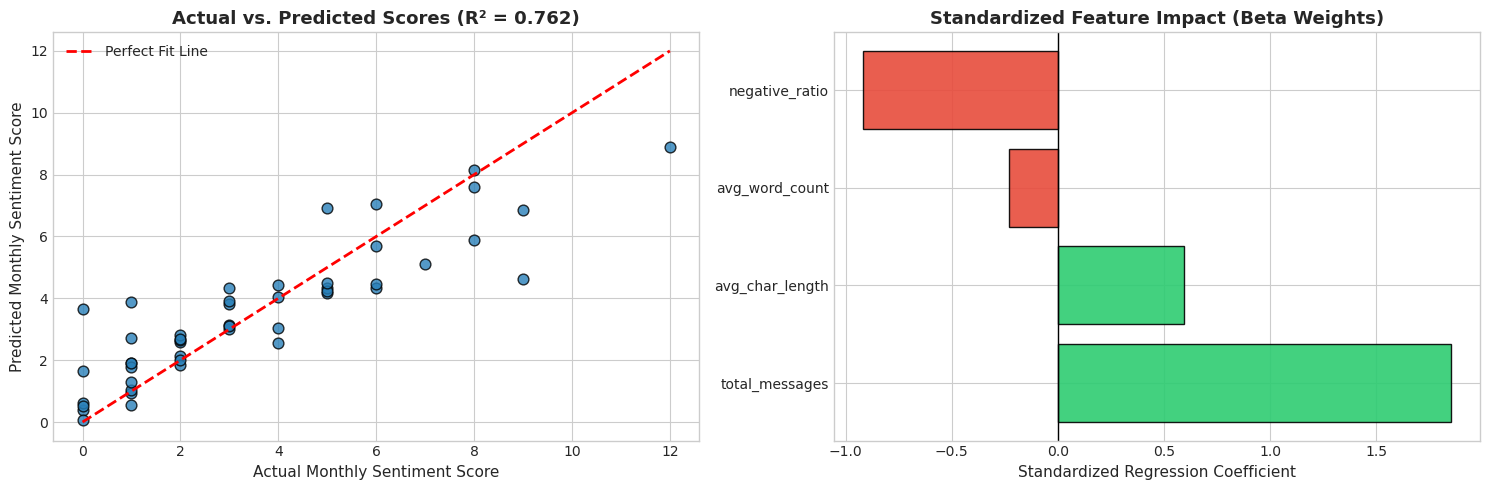

[SAVED] Figure written to visualizations/model_performance_and_coefficients.png

--- Verification of Generated Output Deliverables ---
[FOUND] monthly_employee_scores.csv
[FOUND] employee_rankings.csv
[FOUND] flight_risk_employees.csv
[FOUND] visualizations/sentiment_distribution_and_trends.png
[FOUND] visualizations/sentiment_wordcount_distribution.png
[FOUND] visualizations/flight_risk_distribution.png
[FOUND] visualizations/model_performance_and_coefficients.png


In [19]:
# Cell 18: Regression Diagnostic Visualizations & Output Verification
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 1. Actual vs Predicted Scatter Plot
axes[0].scatter(y_test, y_pred, color='#2980b9', edgecolors='black', alpha=0.8, s=60)
min_val = min(y_test.min(), y_pred.min())
max_val = max(y_test.max(), y_pred.max())
axes[0].plot([min_val, max_val], [min_val, max_val], 'r--', lw=2, label='Perfect Fit Line')
axes[0].set_title(f'Actual vs. Predicted Scores (R² = {r2:.3f})', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Actual Monthly Sentiment Score', fontsize=11)
axes[0].set_ylabel('Predicted Monthly Sentiment Score', fontsize=11)
axes[0].legend()

# 2. Standardized Feature Weight Bar Chart
bar_cols = ['#2ecc71' if b > 0 else '#e74c3c' for b in coef_table['Standardized_Coefficient (Beta)']]
axes[1].barh(coef_table['Feature'], coef_table['Standardized_Coefficient (Beta)'], color=bar_cols, edgecolor='black', alpha=0.9)
axes[1].axvline(0, color='black', lw=1)
axes[1].set_title('Standardized Feature Impact (Beta Weights)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Standardized Regression Coefficient', fontsize=11)

plt.tight_layout()
plt.savefig('visualizations/model_performance_and_coefficients.png', dpi=300)
plt.show()
print("[SAVED] Figure written to visualizations/model_performance_and_coefficients.png")

# Deliverables Check
print("\n--- Verification of Generated Output Deliverables ---")
files_to_check = [
    'monthly_employee_scores.csv',
    'employee_rankings.csv',
    'flight_risk_employees.csv',
    'visualizations/sentiment_distribution_and_trends.png',
    'visualizations/sentiment_wordcount_distribution.png',
    'visualizations/flight_risk_distribution.png',
    'visualizations/model_performance_and_coefficients.png'
]
for f in files_to_check:
    status = "FOUND" if os.path.exists(f) else "NOT FOUND"
    print(f"[{status}] {f}")